In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def expan(img, cmin, cmax):
    salida = np.zeros_like(img, dtype=np.uint8)

    filas, cols = img.shape
    for i in range(filas):
        for j in range(cols):
            ND = img[i, j]
            if ND <= cmin:
                salida[i, j] = 0
            elif ND >= cmax:
                salida[i, j] = 255
            else:
                salida[i, j] = int(((ND - cmin) * 255) / (cmax - cmin))

    return salida

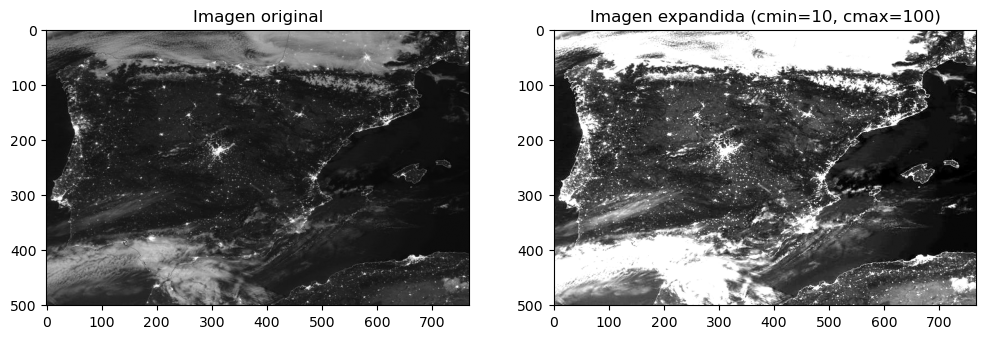

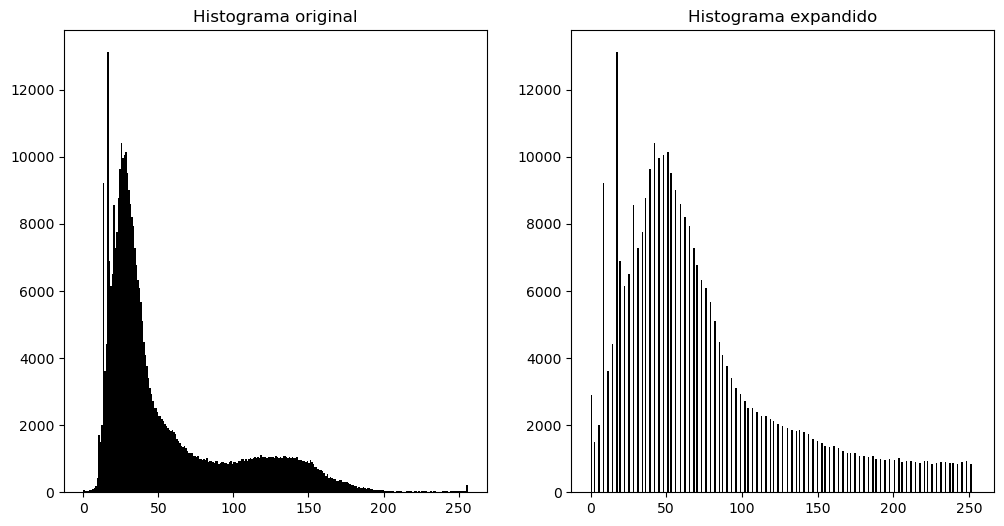

In [4]:
img = cv2.imread("satelite.jpg", cv2.IMREAD_GRAYSCALE)

cmin, cmax = 10, 100
img_exp = expan(img, cmin, cmax)

#Imágenes
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Imagen original")

plt.subplot(1,2,2)
plt.imshow(img_exp, cmap="gray")
plt.title(f"Imagen expandida (cmin={cmin}, cmax={cmax})")
plt.show()

#Histogramas
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.hist(img.ravel(), bins=256, range=[0,256], color='black')
plt.title("Histograma original")

plt.subplot(1,2,2)
plt.hist(img_exp.ravel(), bins=255, range=[0,254], color='black')
plt.title("Histograma expandido")
plt.show()
